# Employee Attrition Prediction Models
**Dataset:** IBM HR Analytics (`WA_Fn-UseC_-HR-Employee-Attrition.csv`)
**Tasks:** Classification (Logistic Regression, Decision Tree, Random Forest, XGBoost) + optional Regression
**Evaluation:** Accuracy, Precision, Recall, F1, ROC-AUC | **Improvement:** Hyperparameter tuning, Cross-validation, Feature importance

Running all cells (Runtime > Run all) trains everything and **auto-generates both reports**.

## 1. Setup

In [1]:
!pip install -q xgboost shap python-docx tabulate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 7.9 MB/s eta 0:00:00


In [2]:
import os, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RS = 42

# Output folders (these become your GitHub folders)
for d in ["outputs/figures", "outputs/reports", "outputs/results"]:
    os.makedirs(d, exist_ok=True)

## 2. Load Data
When asked, upload `WA_Fn-UseC_-HR-Employee-Attrition.csv`.

In [3]:
CSV = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
if not os.path.exists(CSV):
    from google.colab import files
    files.upload()

df = pd.read_csv(CSV)
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
df.head()

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition.csv
Shape: (1470, 35)
Missing values: 0 | Duplicates: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 3. Exploratory Data Analysis

Overall attrition rate: 16.1%


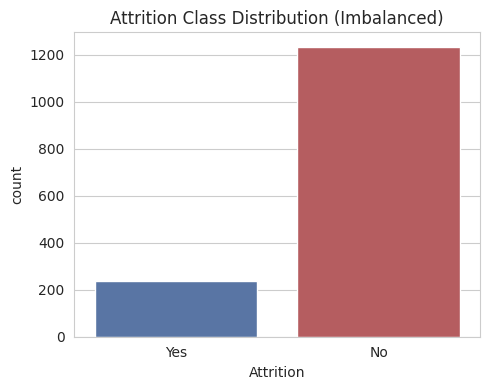

In [4]:
att_rate = (df["Attrition"] == "Yes").mean()
print(f"Overall attrition rate: {att_rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="Attrition", data=df, ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_title("Attrition Class Distribution (Imbalanced)")
plt.tight_layout(); plt.savefig("outputs/figures/01_class_distribution.png", dpi=150); plt.show()

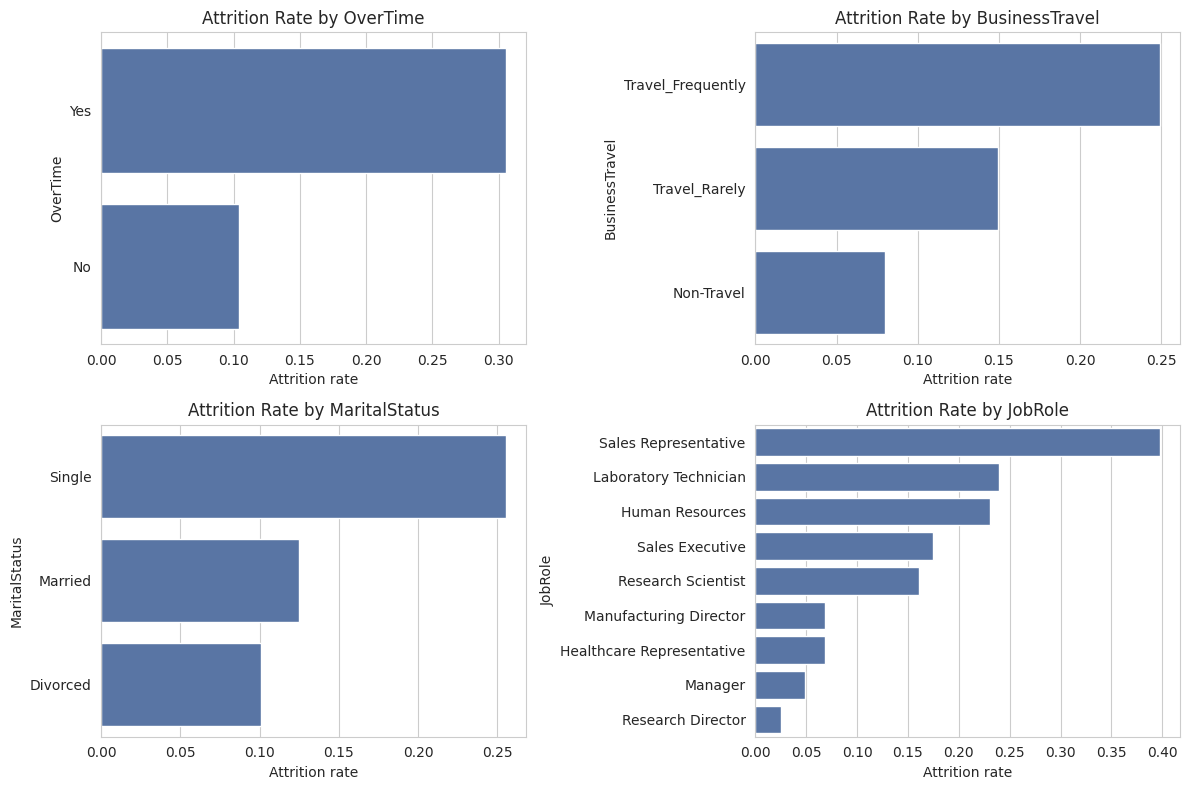

In [5]:
# Attrition rate by key categorical drivers
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["OverTime", "BusinessTravel", "MaritalStatus", "JobRole"]):
    rate = df.groupby(col)["Attrition"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="#4C72B0")
    ax.set_title(f"Attrition Rate by {col}"); ax.set_xlabel("Attrition rate")
plt.tight_layout(); plt.savefig("outputs/figures/02_attrition_by_category.png", dpi=150); plt.show()

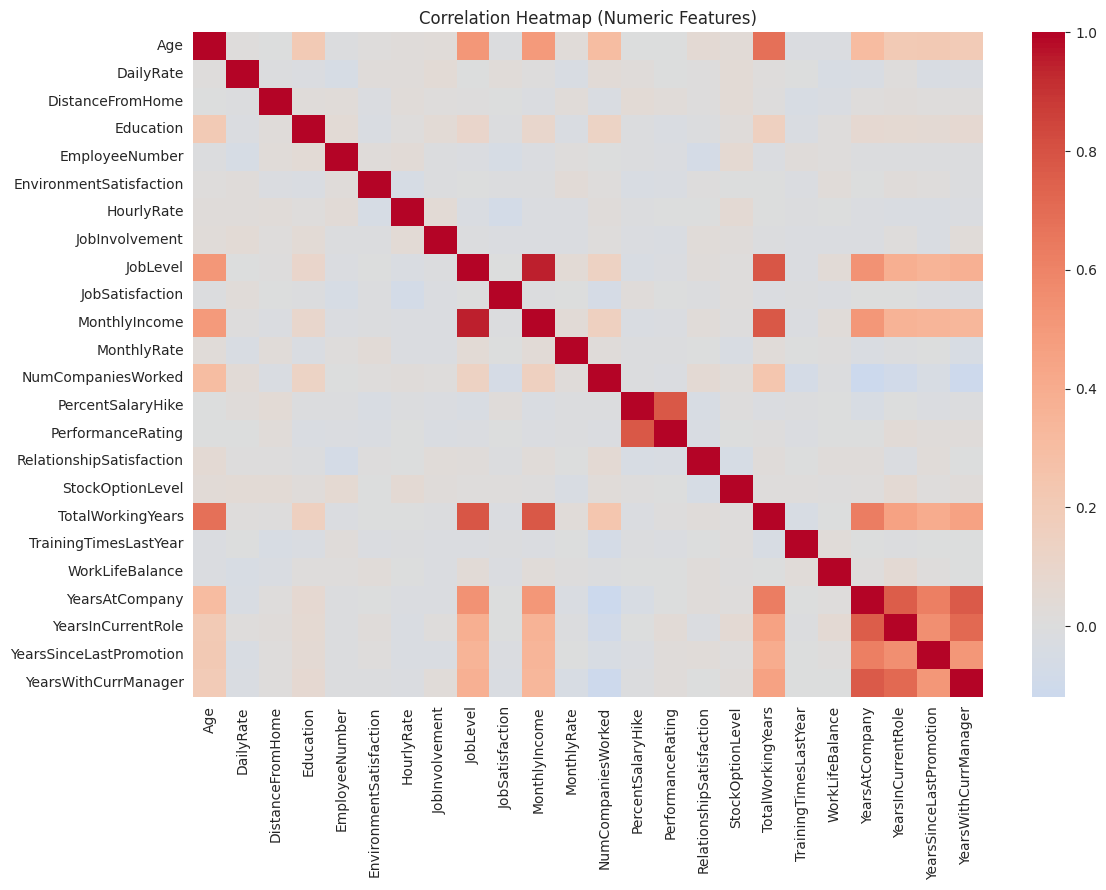

In [6]:
num_df = df.select_dtypes(include=np.number).drop(columns=["EmployeeCount", "StandardHours"], errors="ignore")
plt.figure(figsize=(12, 9))
sns.heatmap(num_df.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap (Numeric Features)")
plt.tight_layout(); plt.savefig("outputs/figures/03_correlation_heatmap.png", dpi=150); plt.show()

## 4. Preprocessing
- Drop useless columns (constant values or ID): `EmployeeCount`, `Over18`, `StandardHours`, `EmployeeNumber`
- Encode target: Yes = 1, No = 0
- Scale numeric columns + one-hot encode categorical columns (inside a Pipeline, so no data leakage)
- Stratified 80/20 train-test split

In [7]:
df_clean = df.drop(columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"])
df_clean["Attrition"] = df_clean["Attrition"].map({"Yes": 1, "No": 0})

X = df_clean.drop(columns=["Attrition"])
y = df_clean["Attrition"]
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Attrition rate  train: %.1f%%  test: %.1f%%" % (y_train.mean() * 100, y_test.mean() * 100))

Train: (1176, 30) | Test: (294, 30)
Attrition rate  train: 16.2%  test: 16.0%


## 5. Baseline Models
Class imbalance (~16% leavers) is handled with `class_weight="balanced"` (LR, DT, RF) and `scale_pos_weight` (XGBoost).

In [8]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

base_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RS),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RS, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss", scale_pos_weight=pos_weight, random_state=RS),
}
base_pipes = {n: Pipeline([("prep", clone(preprocess)), ("model", m)]) for n, m in base_models.items()}

def evaluate(model, X_te, y_te, name):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {"Model": name,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred, zero_division=0),
            "Recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "ROC-AUC": roc_auc_score(y_te, proba)}

rows = []
for name, pipe in base_pipes.items():
    pipe.fit(X_train, y_train)
    rows.append(evaluate(pipe, X_test, y_test, name))
baseline_df = pd.DataFrame(rows).round(3)
baseline_df.to_csv("outputs/results/baseline_test_metrics.csv", index=False)
baseline_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.752,0.349,0.638,0.451,0.803
1,Decision Tree,0.755,0.264,0.298,0.280,0.570
2,Random Forest,0.847,0.625,0.106,0.182,0.783
3,XGBoost,0.854,0.583,0.298,0.394,0.779


## 6. Cross-Validation (5-fold, stratified)

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc"}

cv_rows = []
for name, pipe in base_pipes.items():
    res = cross_validate(clone(pipe), X_train, y_train, cv=skf, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    for k in scoring:
        row[k] = f"{res['test_' + k].mean():.3f} ± {res['test_' + k].std():.3f}"
    cv_rows.append(row)
cv_df = pd.DataFrame(cv_rows)
cv_df.to_csv("outputs/results/baseline_cv_metrics.csv", index=False)
cv_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.753 ± 0.031,0.372 ± 0.038,0.737 ± 0.062,0.492 ± 0.034,0.827 ± 0.028
1,Decision Tree,0.779 ± 0.024,0.304 ± 0.049,0.268 ± 0.054,0.280 ± 0.035,0.573 ± 0.018
2,Random Forest,0.861 ± 0.008,0.876 ± 0.119,0.174 ± 0.057,0.284 ± 0.078,0.804 ± 0.028
3,XGBoost,0.871 ± 0.012,0.656 ± 0.051,0.416 ± 0.073,0.507 ± 0.066,0.801 ± 0.041


## 7. Hyperparameter Tuning (GridSearchCV, scoring = ROC-AUC)

In [10]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Decision Tree": {"model__max_depth": [3, 5, 7, 10], "model__min_samples_leaf": [1, 5, 10],
                      "model__criterion": ["gini", "entropy"]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [5, 10, None],
                      "model__min_samples_leaf": [1, 3, 5]},
    "XGBoost": {"model__n_estimators": [100, 300], "model__max_depth": [3, 5],
                "model__learning_rate": [0.03, 0.1], "model__subsample": [0.8, 1.0]},
}

tuned, tuned_rows, best_params = {}, [], {}
for name, pipe in base_pipes.items():
    gs = GridSearchCV(clone(pipe), param_grids[name], cv=skf, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    best_params[name] = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
    r = evaluate(gs.best_estimator_, X_test, y_test, name)
    r["CV ROC-AUC"] = gs.best_score_
    tuned_rows.append(r)
    print(f"{name}: best CV ROC-AUC = {gs.best_score_:.3f} | params = {best_params[name]}")

tuned_df = pd.DataFrame(tuned_rows).round(3)
tuned_df.to_csv("outputs/results/tuned_test_metrics.csv", index=False)
tuned_df

Logistic Regression: best CV ROC-AUC = 0.831 | params = {'C': 0.1}
Decision Tree: best CV ROC-AUC = 0.718 | params = {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10}
Random Forest: best CV ROC-AUC = 0.810 | params = {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 400}
XGBoost: best CV ROC-AUC = 0.816 | params = {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC
0,Logistic Regression,0.772,0.381,0.681,0.489,0.812,0.831
1,Decision Tree,0.765,0.362,0.617,0.457,0.711,0.718
2,Random Forest,0.833,0.462,0.255,0.329,0.800,0.810
3,XGBoost,0.813,0.429,0.511,0.466,0.770,0.816


## 8. Model Comparison & Best Model
Best model is chosen using **cross-validated ROC-AUC on the training data** (the test set is kept untouched for the final check).

Best model: Logistic Regression


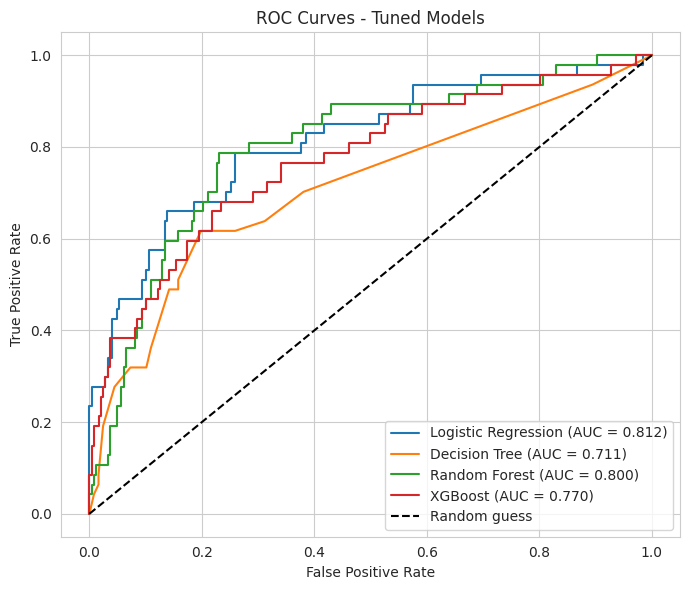

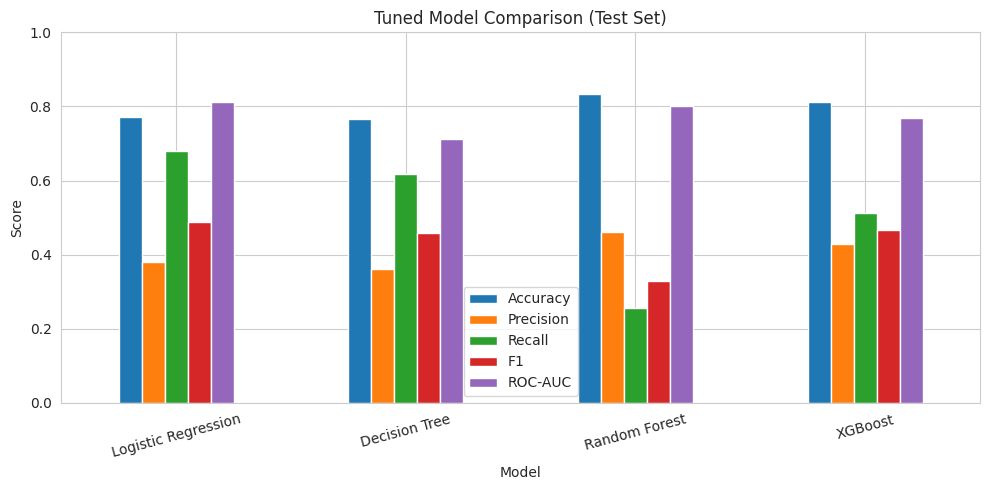

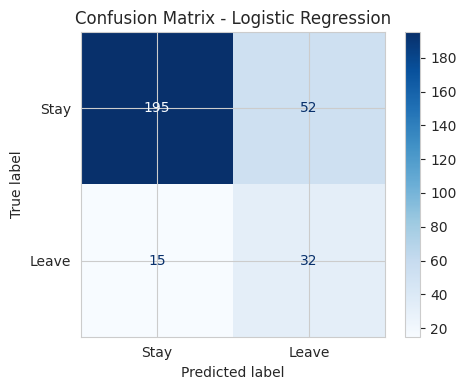

TN=195  FP=52  FN=15  TP=32


In [11]:
best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_model = tuned[best_name].best_estimator_
print("Best model:", best_name)

# Baseline vs Tuned comparison
comp = baseline_df.merge(tuned_df.drop(columns=["CV ROC-AUC"]), on="Model", suffixes=(" (Base)", " (Tuned)"))
comp.to_csv("outputs/results/baseline_vs_tuned.csv", index=False)

# ROC curves
plt.figure(figsize=(7, 6))
for name, gs in tuned.items():
    p = gs.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curves - Tuned Models")
plt.legend(); plt.tight_layout(); plt.savefig("outputs/figures/04_roc_curves.png", dpi=150); plt.show()

# Metric comparison bar chart
tuned_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(10, 5))
plt.title("Tuned Model Comparison (Test Set)"); plt.ylabel("Score"); plt.xticks(rotation=15); plt.ylim(0, 1)
plt.tight_layout(); plt.savefig("outputs/figures/05_model_comparison.png", dpi=150); plt.show()

# Confusion matrix of best model
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=["Stay", "Leave"],
                                      cmap="Blues", ax=ax)
ax.set_title(f"Confusion Matrix - {best_name}")
plt.tight_layout(); plt.savefig("outputs/figures/06_confusion_matrix.png", dpi=150); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, best_model.predict(X_test)).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

In [12]:
# Threshold analysis for the best model (recall vs precision trade-off)
proba_best = best_model.predict_proba(X_test)[:, 1]
thr_rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pr = (proba_best >= t).astype(int)
    thr_rows.append({"Threshold": t, "Precision": precision_score(y_test, pr, zero_division=0),
                     "Recall": recall_score(y_test, pr), "F1": f1_score(y_test, pr),
                     "Employees flagged": int(pr.sum())})
thr_df = pd.DataFrame(thr_rows).round(3)
thr_df.to_csv("outputs/results/threshold_analysis.csv", index=False)
thr_df

,Threshold,Precision,Recall,F1,Employees flagged
0,0.2,0.223,0.936,0.361,197
1,0.3,0.274,0.851,0.415,146
2,0.4,0.325,0.787,0.460,114
3,0.5,0.381,0.681,0.489,84
4,0.6,0.466,0.574,0.514,58


## 9. Feature Importance

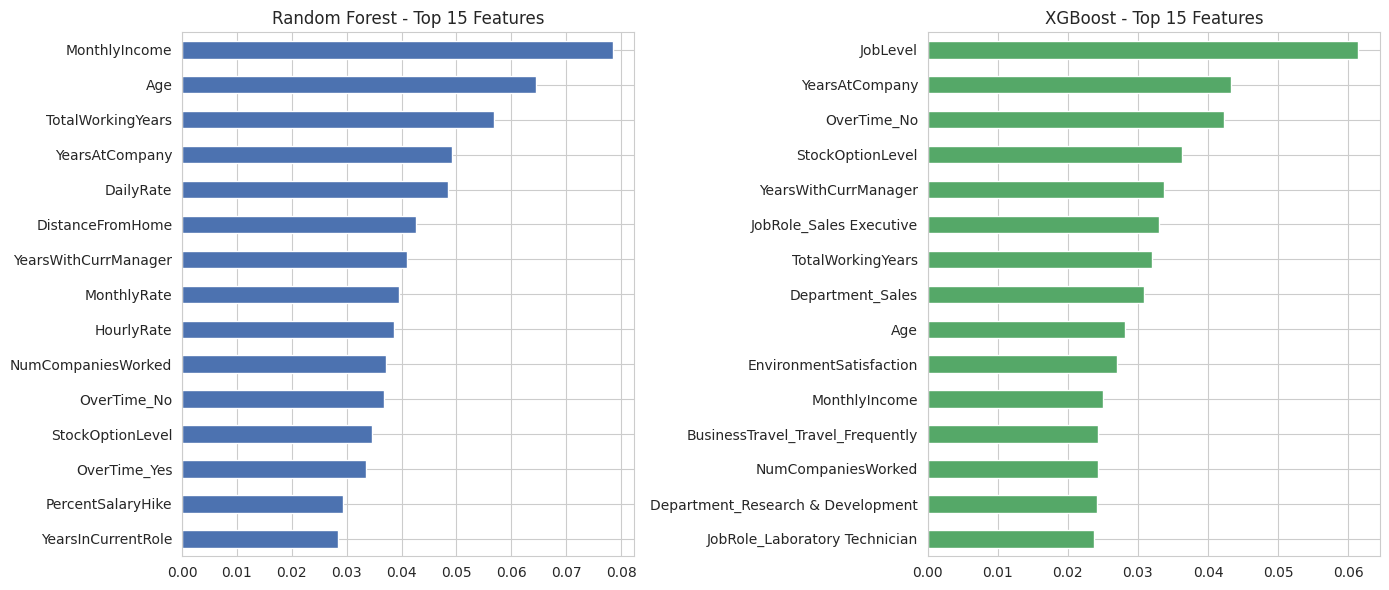

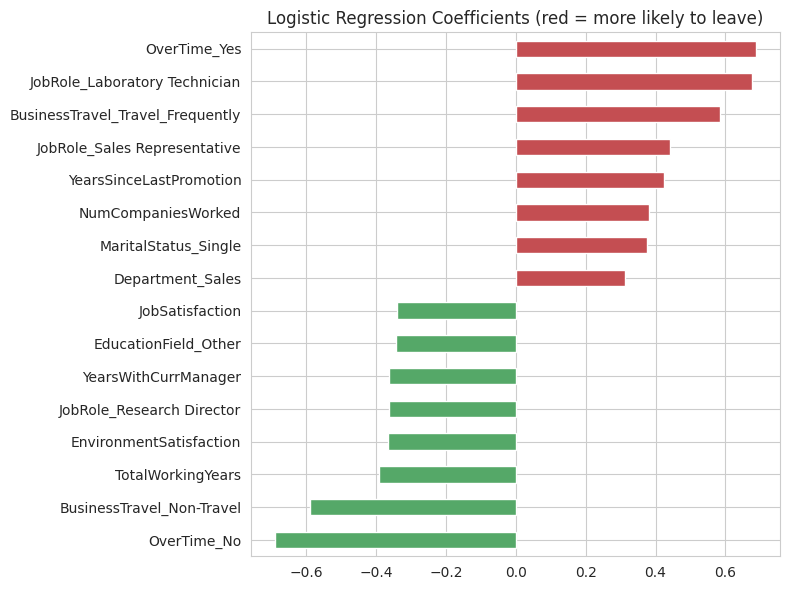

In [13]:
def clean_names(names):
    return [n.replace("num__", "").replace("cat__", "") for n in names]

feat_names = clean_names(tuned["Random Forest"].best_estimator_.named_steps["prep"].get_feature_names_out())

rf_imp = pd.Series(tuned["Random Forest"].best_estimator_.named_steps["model"].feature_importances_,
                   index=feat_names).sort_values(ascending=False)
xgb_imp = pd.Series(tuned["XGBoost"].best_estimator_.named_steps["model"].feature_importances_,
                    index=feat_names).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
rf_imp.head(15)[::-1].plot(kind="barh", ax=axes[0], color="#4C72B0"); axes[0].set_title("Random Forest - Top 15 Features")
xgb_imp.head(15)[::-1].plot(kind="barh", ax=axes[1], color="#55A868"); axes[1].set_title("XGBoost - Top 15 Features")
plt.tight_layout(); plt.savefig("outputs/figures/07_feature_importance.png", dpi=150); plt.show()

# Logistic Regression coefficients (positive = increases attrition risk)
lr_coef = pd.Series(tuned["Logistic Regression"].best_estimator_.named_steps["model"].coef_[0],
                    index=feat_names).sort_values()
top_lr = pd.concat([lr_coef.head(8), lr_coef.tail(8)])
plt.figure(figsize=(8, 6))
top_lr.plot(kind="barh", color=["#55A868" if v < 0 else "#C44E52" for v in top_lr])
plt.title("Logistic Regression Coefficients (red = more likely to leave)")
plt.tight_layout(); plt.savefig("outputs/figures/08_logistic_coefficients.png", dpi=150); plt.show()

rf_imp.head(20).round(4).to_csv("outputs/results/rf_top20_feature_importance.csv", header=["importance"])

## 10. SHAP Explainability (XGBoost)

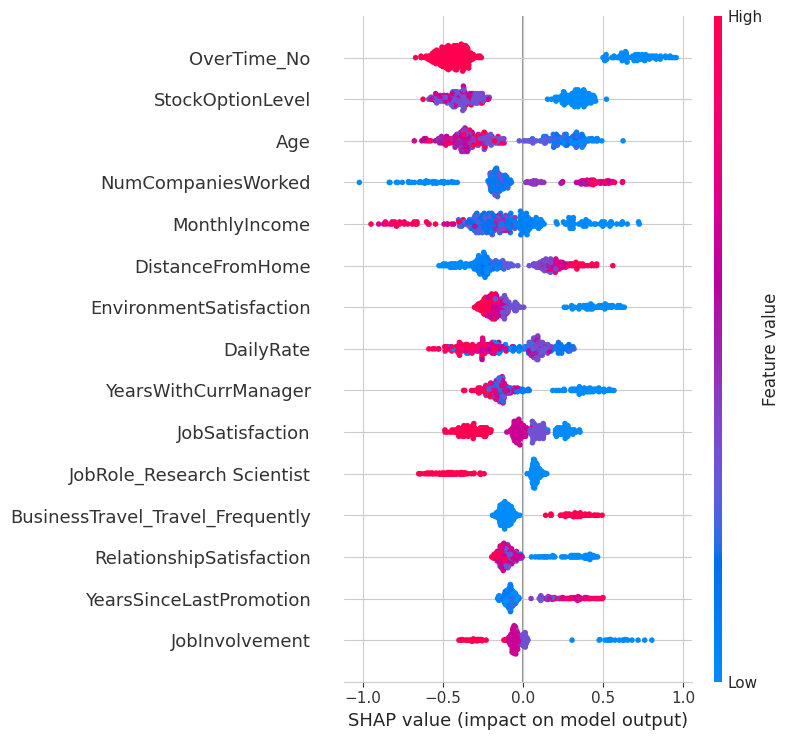

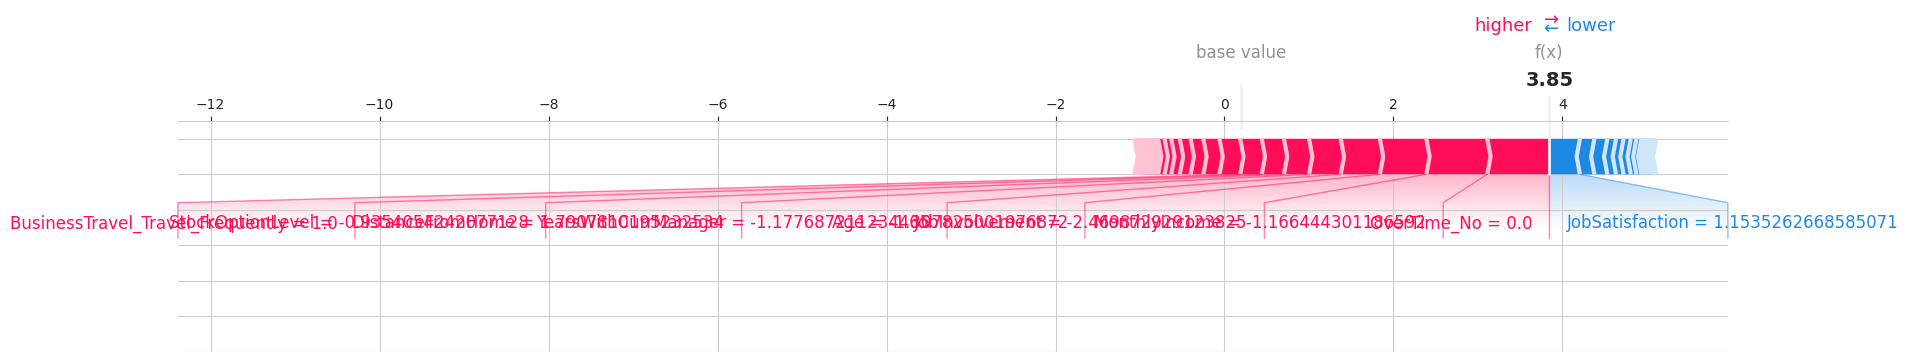

In [14]:
shap_ok = False
try:
    import shap
    xgb_pipe = tuned["XGBoost"].best_estimator_
    Xt = xgb_pipe.named_steps["prep"].transform(X_test)
    Xt = Xt.toarray() if hasattr(Xt, "toarray") else np.asarray(Xt)
    explainer = shap.TreeExplainer(xgb_pipe.named_steps["model"])
    sv = explainer.shap_values(Xt)

    plt.figure()
    shap.summary_plot(sv, Xt, feature_names=feat_names, show=False, max_display=15)
    plt.tight_layout(); plt.savefig("outputs/figures/09_shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

    # Force plot for one employee predicted as "leave" (highest risk)
    i = int(np.argmax(xgb_pipe.predict_proba(X_test)[:, 1]))
    ev = float(np.array(explainer.expected_value).ravel()[0])
    shap.force_plot(ev, sv[i], Xt[i], feature_names=feat_names, matplotlib=True, show=False)
    plt.savefig("outputs/figures/10_shap_force_plot.png", dpi=150, bbox_inches="tight"); plt.show()
    shap_ok = True
except Exception as e:
    print("SHAP step skipped:", e)

## 11. Optional Regression Task - Predict Job Satisfaction Score (1-4)

In [15]:
Xr = df_clean.drop(columns=["JobSatisfaction", "Attrition"])
yr = df_clean["JobSatisfaction"]
cat_r = Xr.select_dtypes(include="object").columns.tolist()
num_r = [c for c in Xr.columns if c not in cat_r]
prep_r = ColumnTransformer([("num", StandardScaler(), num_r), ("cat", OneHotEncoder(handle_unknown="ignore"), cat_r)])

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=RS)
reg_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RS, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=RS),
}
reg_rows = []
for name, m in reg_models.items():
    p = Pipeline([("prep", clone(prep_r)), ("model", m)]).fit(Xr_tr, yr_tr)
    pred = p.predict(Xr_te)
    reg_rows.append({"Model": name, "MAE": mean_absolute_error(yr_te, pred),
                     "RMSE": np.sqrt(mean_squared_error(yr_te, pred)), "R2": r2_score(yr_te, pred)})
reg_df = pd.DataFrame(reg_rows).round(3)
reg_df.to_csv("outputs/results/regression_metrics.csv", index=False)
reg_df

,Model,MAE,RMSE,R2
0,Linear Regression,0.975,1.155,-0.054
1,Random Forest Regressor,0.969,1.138,-0.025
2,XGBoost Regressor,0.993,1.167,-0.077


## 12. Auto-Generate Reports (Word files)
Numbers, tables and charts below come directly from your results above.

In [16]:
from docx import Document
from docx.shared import Inches

def add_df_table(doc, d, decimals=3):
    t = doc.add_table(rows=1, cols=len(d.columns)); t.style = "Light Grid Accent 1"
    for i, c in enumerate(d.columns):
        t.rows[0].cells[i].text = str(c)
    for _, r in d.iterrows():
        cells = t.add_row().cells
        for i, v in enumerate(r):
            cells[i].text = f"{v:.{decimals}f}" if isinstance(v, (float, np.floating)) else str(v)

def add_fig(doc, path, caption, width=6.0):
    if os.path.exists(path):
        doc.add_picture(path, width=Inches(width))
        cp = doc.add_paragraph(); cp.add_run(caption).italic = True

def bullets(doc, items):
    for it in items:
        doc.add_paragraph(it, style="List Bullet")

best_row = tuned_df[tuned_df["Model"] == best_name].iloc[0]
n_total, n_leave = len(df), int((df["Attrition"] == "Yes").sum())

# ---------------- EVALUATION REPORT ----------------
doc = Document()
doc.add_heading("Employee Attrition Prediction - Evaluation Report", 0)

doc.add_heading("1. Objective and Dataset", 1)
doc.add_paragraph(
    f"The goal is to predict whether an employee will leave the company (Attrition = Yes) using the IBM HR Analytics dataset. "
    f"The dataset contains {n_total} employees and {df.shape[1]} columns; {n_leave} employees ({att_rate:.1%}) left, so the classes are imbalanced. "
    f"There were no missing values and {int(df.duplicated().sum())} duplicate rows.")
add_fig(doc, "outputs/figures/01_class_distribution.png", "Figure 1: Attrition class distribution", 3.5)

doc.add_heading("2. Methodology", 1)
bullets(doc, [
    "Removed non-informative columns: EmployeeCount, Over18, StandardHours (constants) and EmployeeNumber (ID).",
    "Target encoded as Yes = 1, No = 0. Numeric features standardised; categorical features one-hot encoded inside a scikit-learn Pipeline to avoid data leakage.",
    "Stratified 80/20 train-test split (random_state = 42) to keep the attrition ratio equal in both sets.",
    "Class imbalance handled with class_weight='balanced' (Logistic Regression, Decision Tree, Random Forest) and scale_pos_weight (XGBoost).",
    "Models: Logistic Regression, Decision Tree, Random Forest, XGBoost.",
    "Metrics: Accuracy, Precision, Recall, F1 and ROC-AUC. Because only about 16% of employees leave, accuracy alone is misleading, so Recall, F1 and ROC-AUC are emphasised.",
    "Improvement: 5-fold stratified cross-validation, GridSearchCV hyperparameter tuning (scoring = ROC-AUC) and feature importance / SHAP analysis.",
])

doc.add_heading("3. Baseline Results (Test Set)", 1)
add_df_table(doc, baseline_df)
doc.add_heading("4. Cross-Validation Results (Baseline, mean ± std over 5 folds)", 1)
add_df_table(doc, cv_df)

doc.add_heading("5. Hyperparameter Tuning", 1)
doc.add_paragraph("Best parameters found by GridSearchCV (5-fold, scoring = ROC-AUC):")
bullets(doc, [f"{n}: {p}" for n, p in best_params.items()])
doc.add_paragraph("Tuned model performance on the test set:")
add_df_table(doc, tuned_df)
doc.add_paragraph("")
doc.add_paragraph("Baseline vs tuned (see results/baseline_vs_tuned.csv for the full side-by-side table).")
add_fig(doc, "outputs/figures/04_roc_curves.png", "Figure 2: ROC curves of tuned models")
add_fig(doc, "outputs/figures/05_model_comparison.png", "Figure 3: Metric comparison of tuned models")

doc.add_heading("6. Best Model", 1)
doc.add_paragraph(
    f"{best_name} was selected because it had the highest cross-validated ROC-AUC ({tuned[best_name].best_score_:.3f}) on the training data. "
    f"On the untouched test set it achieved Accuracy {best_row['Accuracy']:.3f}, Precision {best_row['Precision']:.3f}, "
    f"Recall {best_row['Recall']:.3f}, F1 {best_row['F1']:.3f} and ROC-AUC {best_row['ROC-AUC']:.3f}. "
    f"The confusion matrix shows {tp} leavers correctly caught (TP), {fn} leavers missed (FN), {fp} false alarms (FP) and {tn} stayers correctly identified (TN).")
add_fig(doc, "outputs/figures/06_confusion_matrix.png", "Figure 4: Confusion matrix of the best model", 3.5)
doc.add_paragraph("Effect of the decision threshold (lower threshold = more leavers caught, more false alarms):")
add_df_table(doc, thr_df)

doc.add_heading("7. Feature Importance and Explainability", 1)
doc.add_paragraph("Top features according to the tuned Random Forest: " + ", ".join(rf_imp.head(8).index) + ".")
add_fig(doc, "outputs/figures/07_feature_importance.png", "Figure 5: Feature importance (Random Forest and XGBoost)")
add_fig(doc, "outputs/figures/08_logistic_coefficients.png", "Figure 6: Logistic Regression coefficients", 5.0)
if shap_ok:
    add_fig(doc, "outputs/figures/09_shap_summary.png", "Figure 7: SHAP summary plot (XGBoost)", 5.5)
    add_fig(doc, "outputs/figures/10_shap_force_plot.png", "Figure 8: SHAP force plot for the highest-risk employee in the test set", 6.3)

doc.add_heading("8. Optional Regression: Predicting Job Satisfaction (1-4)", 1)
add_df_table(doc, reg_df)
doc.add_paragraph(
    f"The best regression model by R2 was {reg_df.sort_values('R2').iloc[-1]['Model']} (R2 = {reg_df['R2'].max():.3f}). "
    "Job satisfaction is a 1-4 survey rating and is only weakly explained by the other HR fields, so low R2 values are expected. "
    "This task is exploratory and should not be used for individual decisions.")

doc.add_heading("9. Limitations", 1)
bullets(doc, [
    "The dataset is a fictional, relatively small sample (about 1,470 rows), so results may not generalise to a real company.",
    f"Only {n_leave} employees left, so metrics such as Recall and Precision can change noticeably with a different split.",
    "Feature importance shows association, not cause.",
    "Further work: SMOTE comparison, threshold tuning based on cost of losing an employee, and testing on newer data.",
])
doc.save("outputs/reports/Evaluation_Report.docx")

# ---------------- BUSINESS INTERPRETATION REPORT ----------------
def base_col(feature):
    if feature in num_cols:
        return feature
    for c in sorted(cat_cols, key=len, reverse=True):
        if feature.startswith(c + "_"):
            return c
    return feature

col_imp = rf_imp.groupby([base_col(f) for f in rf_imp.index]).sum().sort_values(ascending=False)
top_cols = list(col_imp.head(8).index)

def describe_driver(col):
    if col in num_cols:
        l = df_clean.loc[df_clean.Attrition == 1, col].mean()
        s = df_clean.loc[df_clean.Attrition == 0, col].mean()
        return f"Employees who left had an average {col} of {l:.1f} versus {s:.1f} for those who stayed."
    rates = df_clean.groupby(col)["Attrition"].mean().sort_values(ascending=False)
    return (f"Attrition is highest for '{rates.index[0]}' ({rates.iloc[0]:.1%}) and lowest for "
            f"'{rates.index[-1]}' ({rates.iloc[-1]:.1%}).")

actions = {
    "OverTime": "Review workloads and overtime policy; cap overtime hours, rebalance work or add headcount in heavy-overtime teams.",
    "MonthlyIncome": "Benchmark pay against the market and review compensation for low-paid roles with high attrition.",
    "Age": "Offer career-stage-specific support (mentoring and growth paths for younger staff, flexibility for senior staff). Do not use age to make individual decisions.",
    "TotalWorkingYears": "Create clear progression paths for early-career employees, who tend to be the most mobile.",
    "YearsAtCompany": "Run stay interviews and onboarding check-ins in the first years, when leaving risk is highest.",
    "YearsInCurrentRole": "Offer role rotation or internal moves to employees who have been in the same role for long.",
    "YearsWithCurrManager": "Train managers and monitor team-level attrition; consider manager-change check-ins.",
    "YearsSinceLastPromotion": "Make promotion and growth discussions a regular, tracked part of reviews.",
    "StockOptionLevel": "Consider extending stock or long-term incentives to groups with high attrition.",
    "JobLevel": "Improve progression from junior levels and review level-based pay gaps.",
    "JobRole": "Run role-specific retention plans for the roles with the highest attrition.",
    "MaritalStatus": "Offer flexible-work and benefits options that fit different life situations (use only for planning, never to treat individuals differently).",
    "DistanceFromHome": "Offer remote or hybrid work, commute support or relocation help for employees with long commutes.",
    "BusinessTravel": "Limit frequent travel where possible and compensate or rotate frequent travellers.",
    "JobSatisfaction": "Track satisfaction with pulse surveys and act quickly on low scores.",
    "EnvironmentSatisfaction": "Improve workplace environment and tools where scores are low.",
    "WorkLifeBalance": "Promote flexible schedules and healthy-workload practices.",
    "NumCompaniesWorked": "Employees with many past employers may leave sooner; focus on engagement and growth early on.",
    "Department": "Compare attrition across departments and target the highest-risk teams.",
    "JobInvolvement": "Increase ownership and meaningful work for employees with low involvement.",
    "PercentSalaryHike": "Review raise policy; small raises may push employees to look elsewhere.",
    "TrainingTimesLastYear": "Invest in training and development opportunities.",
}
default_action = "Monitor this factor and investigate with HR before acting."

bdoc = Document()
bdoc.add_heading("Employee Attrition - Business Interpretation Report", 0)

bdoc.add_heading("1. Business Problem", 1)
bdoc.add_paragraph(
    f"Employee turnover is expensive: recruiting, onboarding, lost knowledge and lower team morale. In this dataset {att_rate:.1%} of employees "
    f"({n_leave} of {n_total}) left the company. The aim of this project is to identify who is at risk of leaving and why, "
    "so HR can act early with targeted retention actions.")

bdoc.add_heading("2. What the Model Tells Us", 1)
bdoc.add_paragraph(
    f"The best model, {best_name}, correctly ranks leavers above stayers with a ROC-AUC of {best_row['ROC-AUC']:.2f}. "
    f"At the standard threshold it catches {best_row['Recall']:.0%} of employees who actually leave (Recall) "
    f"and {best_row['Precision']:.0%} of the employees it flags really do leave (Precision).")
doc_note = ("In plain words: the model works as an early-warning list, not a certainty. "
            "Some flagged employees will not leave, and some leavers will be missed.")
bdoc.add_paragraph(doc_note)

bdoc.add_heading("3. Main Drivers of Attrition", 1)
bdoc.add_paragraph("The factors below had the strongest influence in the Random Forest model (importance of encoded columns summed per original feature). "
                   "Each point also shows what the data says about leavers vs stayers.")
for c in top_cols:
    bdoc.add_paragraph(f"{c} (importance {col_imp[c]:.3f}): {describe_driver(c)}", style="List Number")
add_fig(bdoc, "outputs/figures/02_attrition_by_category.png", "Figure 1: Attrition rate by key categories")
add_fig(bdoc, "outputs/figures/07_feature_importance.png", "Figure 2: Most important features")
bdoc.add_paragraph("Note: these are associations found in historical data. They show where to look, not proof of cause.")

bdoc.add_heading("4. Recommended Actions", 1)
for c in top_cols:
    bdoc.add_paragraph(f"{c}: {actions.get(c, default_action)}", style="List Bullet")

bdoc.add_heading("5. How HR Can Use the Model", 1)
bullets(bdoc, [
    "Score employees regularly and review the highest-risk group first.",
    "Use the threshold table below to balance catching more leavers (lower threshold) against fewer false alarms (higher threshold).",
    "Start with low-cost actions (stay interviews, workload review) before costly ones (pay changes).",
    "Re-train the model every 6-12 months with new data and track whether actions reduce attrition.",
])
add_df_table(bdoc, thr_df)

bdoc.add_heading("6. Risks and Responsible Use", 1)
bullets(bdoc, [
    "Predictions must support supportive conversations, never punishment, denied promotions or dismissal.",
    "Sensitive attributes (Age, Gender, MaritalStatus) should not drive individual decisions; check the model for unfair patterns.",
    "The dataset is small and fictional; validate on the company's own recent data before real deployment.",
])

bdoc.add_heading("7. Optional Finding: Job Satisfaction Model", 1)
bdoc.add_paragraph(
    f"A model predicting job satisfaction (1-4) reached a best R2 of {reg_df['R2'].max():.2f}, which means satisfaction is hard to predict "
    "from HR records alone. Direct employee surveys are therefore more reliable than a model for measuring satisfaction.")

bdoc.save("outputs/reports/Business_Interpretation_Report.docx")
print("Reports saved in outputs/reports/")

Reports saved in outputs/reports/


## 13. Auto-Generate README.md for GitHub

In [17]:
readme = f"""# Employee Attrition Prediction Models

Predicting employee attrition on the IBM HR Analytics dataset using Logistic Regression, Decision Tree, Random Forest and XGBoost,
plus an optional regression task (Job Satisfaction).

## Project Structure
```
├── README.md
├── requirements.txt
├── data/WA_Fn-UseC_-HR-Employee-Attrition.csv
├── notebooks/Employee_Attrition_Prediction.ipynb
├── reports/Evaluation_Report.docx
├── reports/Business_Interpretation_Report.docx
├── figures/   (charts used in the reports)
└── results/   (metric tables as CSV)
```

## Methods
- Preprocessing: dropped constant/ID columns, scaled numeric features, one-hot encoded categorical features, stratified 80/20 split
- Imbalance handling: class weights / scale_pos_weight
- Evaluation: Accuracy, Precision, Recall, F1, ROC-AUC
- Improvement: 5-fold stratified cross-validation, GridSearchCV tuning, feature importance, SHAP

## Results (test set, tuned models)
{tuned_df.drop(columns=['CV ROC-AUC']).to_markdown(index=False)}

**Best model:** {best_name} (ROC-AUC {best_row['ROC-AUC']:.3f}, Recall {best_row['Recall']:.3f}, F1 {best_row['F1']:.3f})

**Top drivers of attrition:** {", ".join(top_cols[:6])}

## How to Run
1. Open `notebooks/Employee_Attrition_Prediction.ipynb` in Google Colab.
2. Upload `WA_Fn-UseC_-HR-Employee-Attrition.csv` when prompted.
3. Run all cells; reports, figures and results are generated in the `outputs/` folder.

## Reports
- `reports/Evaluation_Report.docx` - methodology, metrics, tuning, feature importance
- `reports/Business_Interpretation_Report.docx` - findings and recommendations for HR
"""
with open("outputs/README.md", "w") as f:
    f.write(readme)

with open("outputs/requirements.txt", "w") as f:
    f.write("pandas\nnumpy\nscikit-learn\nxgboost\nshap\nmatplotlib\nseaborn\npython-docx\ntabulate\n")

## 14. Download Everything

In [18]:
with zipfile.ZipFile("attrition_project_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk("outputs"):
        for fn in fs:
            p = os.path.join(root, fn)
            z.write(p, os.path.relpath(p, "outputs"))
print("Created attrition_project_outputs.zip")
try:
    from google.colab import files
    files.download("attrition_project_outputs.zip")
except ImportError:
    pass

Created attrition_project_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>